# Predicting Early-Grade Reading Fluency in East Africa

**Mission:** To nurture compassionate and responsible young leaders by equipping children aged 7–12 with practical life skills, character development and opportunities to discover their talents through hands-on learning, mentorship and community service.

**Use case:** Predict how many words per minute a primary school child can read, so mentorship programs can find children who need reading support early.

**Dataset:** AHEAD (2008–2022), AFLEARN / DataFirst, University of Cape Town. DOI: https://doi.org/10.25828/2287-mw84

## 1. Import libraries
Tools for data, maths, charts, and reading the ZIP file.

In [2]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", font_scale=1.0)

## 2. Load the data
Load only the 11 columns I need, in small chunks, because the file is very large.

In [3]:
RAW_ZIP = "../data/afr-df-ahead-2008-2022-v2.zip"
RAW_CSV = "afr-df-ahead-2008-2022-v2.csv"

columns_we_need = [
    "country_iso", "admin_div1", "lang_assessment", "location",
    "gender", "age", "grade", "year",
    "fam_word_pm", "list_comp_score_pcnt", "oral_read_pm",
]

pieces = []
with zipfile.ZipFile(RAW_ZIP) as z:
    with z.open(RAW_CSV) as f:
        for chunk in pd.read_csv(f, usecols=columns_we_need, chunksize=20_000, low_memory=False):
            pieces.append(chunk)

raw = pd.concat(pieces, ignore_index=True)
print(raw.shape)

(217127, 11)


## 3. Clean the data
Turn columns into numbers, remove children with missing information, and keep realistic ages (5-14)

In [4]:
numeric_cols = ["lang_assessment", "location", "gender", "age", "grade",
                "year", "fam_word_pm", "list_comp_score_pcnt", "oral_read_pm"]
for col in numeric_cols:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")

df = raw.dropna()
df = df[df["age"].between(5, 14) & (df["grade"] > 0)]
print(df.shape)


(24360, 11)


## 4. Give codes readable names
The dataset stores categories as numbers (for example 1 = Rural). I replace them with names and rename columns clearly.

In [5]:
df["country"] = df["country_iso"].map({"ET": "Ethiopia", "MW": "Malawi",
                                       "RW": "Rwanda", "TZ": "Tanzania"})
df["location"] = df["location"].map({1: "Rural", 2: "Urban"})
df["gender"] = df["gender"].map({0: "Male", 1: "Female"})
df["language"] = df["lang_assessment"].map({
    1: "Chichewa", 8: "Kinyarwanda", 9: "Kiswahili", 28: "Tigrinya",
    29: "Amharic", 30: "Afan Oromo", 31: "Somaligna",
    32: "Sidaamu Afoo", 33: "Hararigna"})

df = df.rename(columns={
    "admin_div1": "region",
    "fam_word_pm": "familiar_words_per_min",
    "list_comp_score_pcnt": "listening_comprehension_pct",
    "oral_read_pm": "words_per_minute"})

df["age"] = df["age"].astype(int)
df["grade"] = df["grade"].astype(int)
df["year"] = df["year"].astype(int)

df = df[["country", "region", "language", "location", "gender", "age", "grade",
         "year", "familiar_words_per_min", "listening_comprehension_pct",
         "words_per_minute"]]
df.head()

,country,region,language,location,gender,age,grade,year,familiar_words_per_min,listening_comprehension_pct,words_per_minute
38503,Ethiopia,1 - Tigray,Tigrinya,Urban,Female,9,3,2010,12.00000,100.000000,12.0
38504,Ethiopia,1 - Tigray,Tigrinya,Urban,Female,8,2,2010,0.00000,80.000001,0.0
38505,Ethiopia,1 - Tigray,Tigrinya,Urban,Male,8,2,2010,57.64706,100.000000,40.0
38506,Ethiopia,1 - Tigray,Tigrinya,Urban,Male,9,3,2010,29.00000,100.000000,18.0
38507,Ethiopia,1 - Tigray,Tigrinya,Urban,Male,10,2,2010,0.00000,100.000000,0.0


## 5. Save the clean dataset
Save the small clean table so it can go on GitHub and be used later by the API.

In [6]:
df.to_csv("../data/ahead_reading_fluency.csv", index=False)
print("Saved", len(df), "rows")

Saved 24360 rows


## 6. Correlation heatmap
Shows how strongly each number column moves together with reading speed.

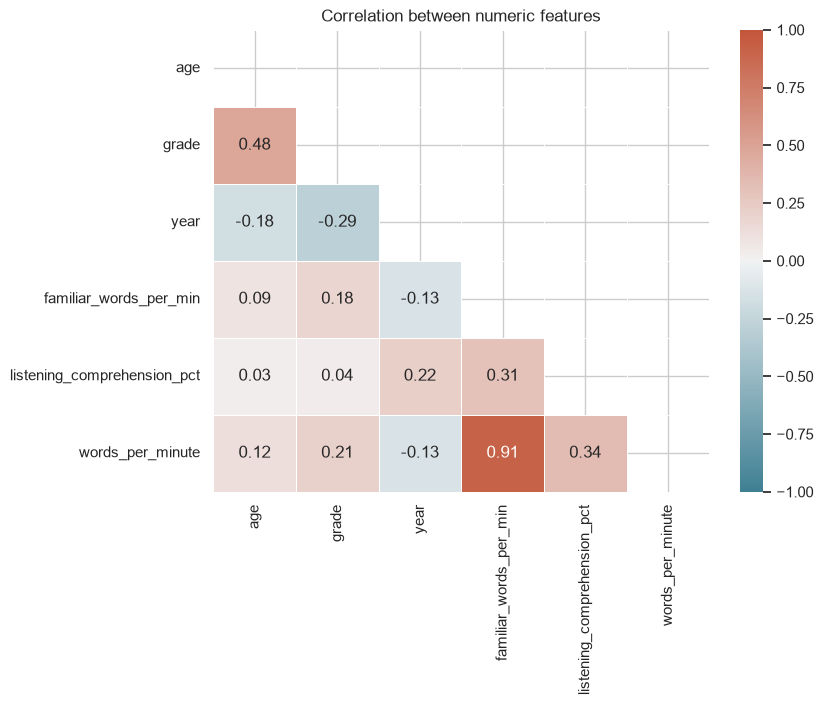

In [7]:
numeric_cols = ["age", "grade", "year", "familiar_words_per_min",
                "listening_comprehension_pct", "words_per_minute"]
corr = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(8, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f",
            cmap=sns.diverging_palette(220, 20, as_cmap=True),
            center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation between numeric features")
plt.show()

## 7. Distribution of reading speed
Shows how many children read at each speed.

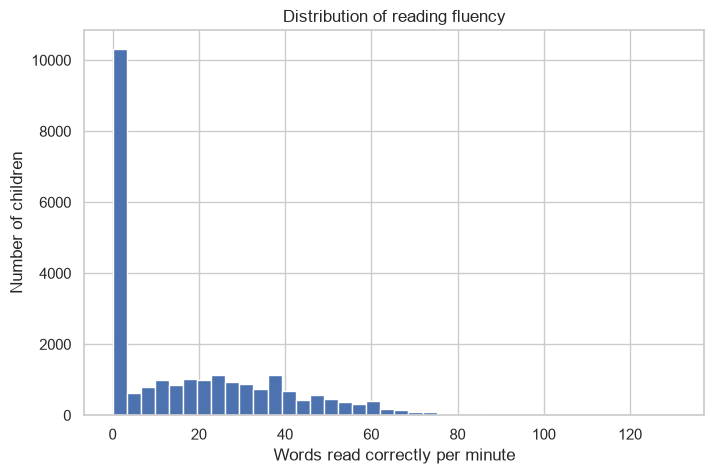

In [8]:
plt.figure(figsize=(8, 5))
plt.hist(df["words_per_minute"], bins=40, color="#4C72B0", edgecolor="white")
plt.xlabel("Words read correctly per minute")
plt.ylabel("Number of children")
plt.title("Distribution of reading fluency")
plt.show()

**What it shows:** Most children read very few words. About 40% of children read 0 words per minute, and only a few read more than 60. The distribution is skewed to the right.

**Decision:** Because of these extreme values, I will compare MSE with Huber loss, which is less sensitive to outliers.

## 8. Reading speed by country and location
Compares average reading speed across countries and between rural and urban schools.

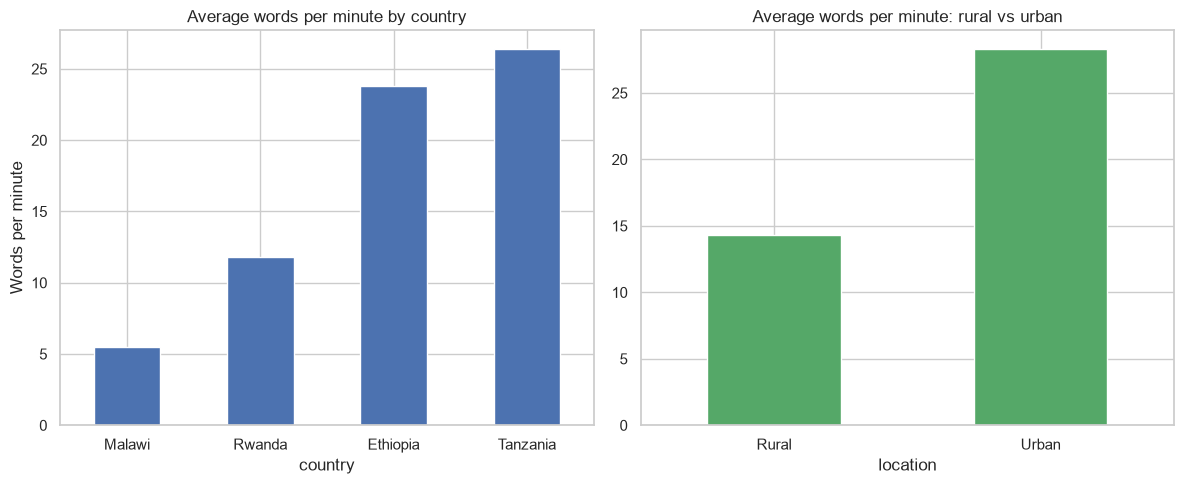

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
df.groupby("country")["words_per_minute"].mean().sort_values().plot(
    kind="bar", ax=axes[0], color="#4C72B0", edgecolor="white")
axes[0].set_title("Average words per minute by country")
axes[0].set_ylabel("Words per minute")
axes[0].tick_params(axis="x", rotation=0)

df.groupby("location")["words_per_minute"].mean().plot(
    kind="bar", ax=axes[1], color="#55A868", edgecolor="white")
axes[1].set_title("Average words per minute: rural vs urban")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**What it shows:** Children in Tanzania and Ethiopia read faster than those in Rwanda and Malawi, and urban children read about twice as fast as rural children (28 vs 14 words per minute).

**Decision:** Country and location clearly affect reading, so I keep them as categorical features. I drop region, because it has 59 categories and mostly repeats the country information.